[All milestones](../START_HERE.ipynb) · [Main solution](../solution/reduced_qubit_hybrid_hourly.ipynb)

# Milestone 1 — understand demand and hand-schedule six hours

Run top to bottom. The checker reports feasibility and cost for the supplied five-plant model.

In [1]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [2]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no remote job. Select an environment that already includes it.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    raise ImportError("Use a qBraid environment with qiskit-aer installed.")

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 1. The plants and the demand

Each row of `data/plants.csv` is one plant, built from a real unit in the RTS-GMLC test grid (see `data/README.md`).

| Column | Meaning |
|---|---|
| `pmin_mw`, `pmax_mw` | When on, the plant makes between pmin and pmax MW |
| `marginal_cost_per_mwh` | Fuel cost of each extra MWh |
| `no_load_cost_per_h` | Cost per hour of just being on |
| `startup_cost` | Paid each time the plant switches on |
| `min_up_h`, `min_down_h` | Once on, it stays on this many hours. Once off, it stays off this many hours. |
| `on_at_start` | 1 if the plant is already running at midnight |

One hour of a plant that is on costs: no-load cost + marginal cost × output, plus the startup cost if it just switched on.

plant     type                              pmin  pmax   $/MWh  no-load $/h  startup $  min up  min down
COAL      coal steam                         140   350   21.69          546     36,750     24h       48h
GAS_CC    gas combined cycle                 168   350   26.84          206     27,650      8h        5h
PEAKER_A  gas combustion turbine              20    50   28.89          443      5,150      3h        3h
PEAKER_B  gas combustion turbine (older)      20    50   39.51          749      5,150      3h        3h
OIL       oil combustion turbine              20    50  101.02          694        130      1h        1h


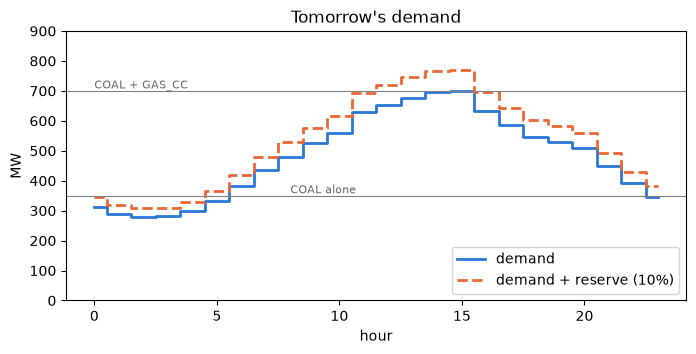

In [3]:
print(f"{'plant':<10}{'type':<32}{'pmin':>6}{'pmax':>6}{'$/MWh':>8}{'no-load $/h':>13}"
      f"{'startup $':>11}{'min up':>8}{'min down':>10}")
for p in plants:
    print(f"{p['plant_id']:<10}{p['type']:<32}{p['pmin_mw']:>6.0f}{p['pmax_mw']:>6.0f}"
          f"{p['marginal_cost_per_mwh']:>8.2f}{p['no_load_cost_per_h']:>13,.0f}"
          f"{p['startup_cost']:>11,.0f}{p['min_up_h']:>7.0f}h{p['min_down_h']:>9.0f}h")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(hours, demand, where="mid", color=COLORS["milp"], lw=2, label="demand")
ax.step(hours, demand + reserve, where="mid", color=COLORS["qaoa"], lw=2, ls="--",
        label="demand + reserve (10%)")
for level, text, x in [(350, "COAL alone", 8), (700, "COAL + GAS_CC", 0)]:
    ax.axhline(level, color="gray", lw=0.8)
    ax.text(x, level + 8, text, color="dimgray", fontsize=8)
ax.set(xlabel="hour", ylabel="MW", title="Tomorrow's demand", ylim=(0, 900))
ax.legend(loc="lower right")
plt.show()

### Milestone 1: schedule 6 hours by hand

Edit `my_schedule`: one row per hour (hours 0 to 5), one column per plant, 1 = on. The checker prints the cost and any rules broken. How close you are to the best possible is yours to find out in Milestone 2. A spreadsheet works too.

In [4]:
#               COAL  GAS_CC  PEAKER_A  PEAKER_B  OIL
my_schedule = [[1,    0,      0,        0,        0],   # hour 0
               [1,    0,      0,        0,        0],   # hour 1
               [1,    0,      0,        0,        0],   # hour 2
               [1,    0,      0,        0,        0],   # hour 3
               [1,    0,      0,        0,        0],   # hour 4
               [1,    0,      0,        0,        1]]   # hour 5: OIL adds capacity for reserve

hand_result = check_schedule(plants, demand[:6], reserve[:6], my_schedule)

Total cost: $44,555  (startups $130, no-load $3,970, energy $40,455)
Valid: every hour meets demand and reserve; no min up/down rule is broken.
